# Model Eğitimi ve Değerlendirme

## Veri Ön İşleme Adımları
1. Mel-spektrogramlar `X_veri.npy` dosyasından yüklenir ve CNN için kanal boyutu eklenir (128×130×1).
2. Etiketler `LabelEncoder` ile sayısallaştırılır (11 sınıf).
3. Veri %80 eğitim / %20 test olarak ayrılır (`random_state=42`).
4. Min-max normalizasyon ile değerler 0-1 aralığına ölçeklenir.

## Model Seçimi Gerekçesi
Mel-spektrogramlar zaman-frekans düzleminde bir "görüntü" gibi düşünülebilir; bu nedenle görüntü işlemede başarılı olan **CNN (Evrişimli Sinir Ağı)** mimarisi tercih edilmiştir. Conv2D katmanları spektrogramdaki harmonik çizgileri ve tını örüntülerini öğrenirken, MaxPooling katmanları boyutu azaltarak hesaplama maliyetini düşürür. Çıkış katmanında 11 sınıf için softmax aktivasyonu kullanılır. Model, karşılaştırma amacıyla 4 varyant halinde geliştirilmiştir (v1 → v4).

**Metodolojik not:** Bu çalışmada ayrı bir doğrulama (validation) seti ayrılmamış; doğrulama için test seti kullanılmıştır. Bu yaklaşım hızlı geri bildirim sağlasa da model seçimini iyimserleştirebilir; ileride eğitim/doğrulama/test üçlü bölme önerilir.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf


print("Veriler yükleniyor...")
X = np.load("X_veri.npy")
y = np.load("y_etiket.npy")


X = X[..., np.newaxis] 


encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
sinif_sayisi = len(np.unique(y_encoded))
sinif_isimleri = encoder.classes_


X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

print("\n--- Veri Hazırlığı Tamamlandı ---")
print(f"Sınıflar: {sinif_isimleri}")
print(f"Eğitim Seti Boyutu (X_train): {X_train.shape}")
print(f"Test Seti Boyutu (X_test): {X_test.shape}")

Veriler yükleniyor...

--- Veri Hazırlığı Tamamlandı ---
Sınıflar: ['cel' 'cla' 'flu' 'gac' 'gel' 'org' 'pia' 'sax' 'tru' 'vio' 'voi']
Eğitim Seti Boyutu (X_train): (5364, 128, 130, 1)
Test Seti Boyutu (X_test): (1341, 128, 130, 1)


In [ ]:
from tensorflow.keras import layers, models


model = models.Sequential([
    Görüntüdeki temel şekilleri (yatay/dikey frekans çizgileri) öğrenir
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 130, 1)),
    layers.MaxPooling2D((2, 2)), 
    Daha karmaşık şekilleri (nota geçişleri, ritim kalıpları) öğrenir
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    Enstrümana özgü detaylı tınıları (timbre) kavrar
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), 
    layers.Dense(sinif_sayisi, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print(model.summary()) 

print("\n--- Model Eğitimi Başlıyor ---")

history = model.fit(X_train, y_train, 
                    epochs=15, 
                    batch_size=32, 
                    validation_data=(X_test, y_test))

C:\Users\ev\Desktop\multi_instrument_recognition\venv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 128, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 62, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 31, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 29, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 11)                  │           1,419 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,483 (12.61 MB)

 Trainable params: 3,305,483 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

None

--- Model Eğitimi Başlıyor ---
Epoch 1/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 29s 165ms/step - accuracy: 0.1068 - loss: 3.0263 - val_accuracy: 0.1037 - val_loss: 2.3912
Epoch 2/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - accuracy: 0.1158 - loss: 2.3843 - val_accuracy: 0.1089 - val_loss: 2.3869
Epoch 3/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - accuracy: 0.1150 - loss: 2.3796 - val_accuracy: 0.1089 - val_loss: 2.3862
Epoch 4/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 28s 166ms/step - accuracy: 0.1122 - loss: 2.3792 - val_accuracy: 0.1089 - val_loss: 2.3863
Epoch 5/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 28s 164ms/step - accuracy: 0.1186 - loss: 2.3777 - val_accuracy: 0.1089 - val_loss: 2.3867
Epoch 6/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - accuracy: 0.1109 - loss: 2.3780 - val_accuracy: 0.1089 - val_loss: 2.3865
Epoch 7/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - accuracy: 0.1137 - loss: 2.3936 - val_accuracy: 0.1037 - val_loss: 2.3866
Epoch 8/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 27s 16

**Yorum:** İlk model (v1) 15 epoch boyunca öğrenememiştir; doğruluk rastgele tahmin seviyesinde (~%11) kalmıştır. Kararsız eğitime karşı v2'de BatchNormalization katmanları eklenmiş ve girişler normalize edilmiştir.

In [ ]:
X_train_norm = (X_train - np.min(X_train)) / (np.max(X_train) - np.min(X_train))
X_test_norm = (X_test - np.min(X_test)) / (np.max(X_test) - np.min(X_test))

model_v2 = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 130, 1)),
    layers.BatchNormalization(), 
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(), 
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(), 
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(sinif_sayisi, activation='softmax')
])

# YENİ MODELİ DERLE VE EĞİT
model_v2.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("\n--- Model v2 Eğitimi Başlıyor ---")
history_v2 = model_v2.fit(X_train_norm, y_train, 
                          epochs=15, 
                          batch_size=32, 
                          validation_data=(X_test_norm, y_test))


--- Model v2 Eğitimi Başlıyor ---
Epoch 1/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 73s 422ms/step - accuracy: 0.1152 - loss: 2.5861 - val_accuracy: 0.0708 - val_loss: 22.1077
Epoch 2/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 68s 408ms/step - accuracy: 0.1167 - loss: 2.4068 - val_accuracy: 0.1283 - val_loss: 11.3088
Epoch 3/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 70s 415ms/step - accuracy: 0.1188 - loss: 2.3986 - val_accuracy: 0.1260 - val_loss: 3.7119
Epoch 4/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 70s 418ms/step - accuracy: 0.1178 - loss: 2.3810 - val_accuracy: 0.1104 - val_loss: 2.3847
Epoch 5/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 70s 414ms/step - accuracy: 0.1182 - loss: 2.3775 - val_accuracy: 0.1096 - val_loss: 2.3932
Epoch 6/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 70s 419ms/step - accuracy: 0.1189 - loss: 2.3866 - val_accuracy: 0.1007 - val_loss: 2.4315
Epoch 7/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 75s 444ms/step - accuracy: 0.1186 - loss: 2.3785 - val_accuracy: 0.1089 - val_loss: 2.3858
Epoch 8/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 71s 42

**Yorum:** v2'de eğitim kaybı düşmeye başlamış ancak doğrulama kaybı dalgalı seyretmiştir; model ezberlemeye (overfitting) yönelmektedir. v3'te aşırı öğrenmeyi azaltmak için Flatten yerine GlobalAveragePooling2D kullanılmış ve öğrenme oranı 0.0005'e düşürülmüştür.

In [ ]:
from tensorflow.keras import layers, models, optimizers


model_v3 = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 130, 1)),
    layers.BatchNormalization(), 
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(), 
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(), 
    layers.MaxPooling2D((2, 2)),

    
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(sinif_sayisi, activation='softmax')
])


özel_optimizer = optimizers.Adam(learning_rate=0.0005)

model_v3.compile(optimizer=özel_optimizer,
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print(model_v3.summary()) 

print("\n--- Model v3 Eğitimi Başlıyor ---")
history_v3 = model_v3.fit(X_train_norm, y_train, 
                          epochs=20, 
                          batch_size=32, 
                          validation_data=(X_test_norm, y_test))

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)                    │ (None, 126, 128, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 126, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 63, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 61, 62, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 61, 62, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 30, 31, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 28, 29, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 28, 29, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 11)                  │           1,419 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,499 (435.54 KB)

 Trainable params: 111,051 (433.79 KB)

 Non-trainable params: 448 (1.75 KB)

None

--- Model v3 Eğitimi Başlıyor ---
Epoch 1/20
168/168 ━━━━━━━━━━━━━━━━━━━━ 75s 436ms/step - accuracy: 0.2176 - loss: 2.2405 - val_accuracy: 0.1089 - val_loss: 2.5251
Epoch 2/20
168/168 ━━━━━━━━━━━━━━━━━━━━ 78s 464ms/step - accuracy: 0.2957 - loss: 2.0654 - val_accuracy: 0.1119 - val_loss: 2.9883
Epoch 3/20
168/168 ━━━━━━━━━━━━━━━━━━━━ 68s 404ms/step - accuracy: 0.3518 - loss: 1.9332 - val_accuracy: 0.1805 - val_loss: 2.8456
Epoch 4/20
168/168 ━━━━━━━━━━━━━━━━━━━━ 64s 381ms/step - accuracy: 0.3943 - loss: 1.8023 - val_accuracy: 0.2453 - val_loss: 2.3775
Epoch 5/20
168/168 ━━━━━━━━━━━━━━━━━━━━ 67s 398ms/step - accuracy: 0.4318 - loss: 1.6876 - val_accuracy: 0.1902 - val_loss: 3.6215
Epoch 6/20
168/168 ━━━━━━━━━━━━━━━━━━━━ 64s 380ms/step - accuracy: 0.4616 - loss: 1.6009 - val_accuracy: 0.1447 - val_loss: 5.9275
Epoch 7/20
168/168 ━━━━━━━━━━━━━━━━━━━━ 64s 381ms/step - accuracy: 0.4892 - loss: 1.5199 - val_accuracy: 0.3266 - val_loss: 2.1472
Epoch 8/20
168/168 ━━━━━━━━━━━━━━━━━━━━ 64s

**Yorum:** v3 modeli, eğitim doğruluğu %72,6'ya ulaşırken doğrulama doğruluğu %52,6 civarında kalmıştır. Eğitim ve doğrulama eğrileri arasındaki belirgin fark ezberleme (overfitting) eğilimini göstermektedir; doğrulama eğrisindeki dalgalanmalar ise veri setinin zorluğuna işaret etmektedir.

In [ ]:

model_v3.save('multi_instrument_model.keras')
print("Model başarıyla diske kaydedildi!")

Model başarıyla diske kaydedildi!


1. Hafıza tazeleniyor: Veriler ve Kayıtlı Model yükleniyor...
2. 1341 test verisi analiz ediliyor...
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step


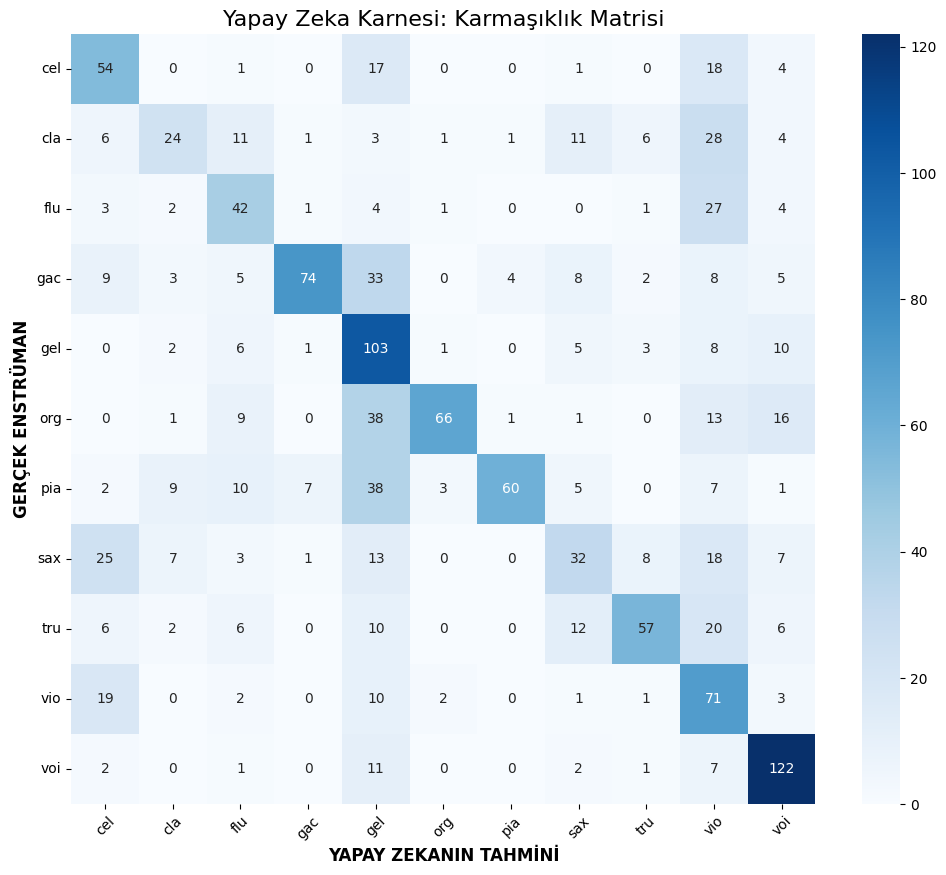


--- Detaylı Sınıflandırma Raporu ---
              precision    recall  f1-score   support

         cel       0.43      0.57      0.49        95
         cla       0.48      0.25      0.33        96
         flu       0.44      0.49      0.46        85
         gac       0.87      0.49      0.63       151
         gel       0.37      0.74      0.49       139
         org       0.89      0.46      0.60       145
         pia       0.91      0.42      0.58       142
         sax       0.41      0.28      0.33       114
         tru       0.72      0.48      0.58       119
         vio       0.32      0.65      0.43       109
         voi       0.67      0.84      0.74       146

    accuracy                           0.53      1341
   macro avg       0.59      0.52      0.51      1341
weighted avg       0.62      0.53      0.53      1341



In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np
import tensorflow as tf

print("1. Hafıza tazeleniyor: Veriler ve Kayıtlı Model yükleniyor...")
X = np.load("X_veri.npy")
y = np.load("y_etiket.npy")

X = X[..., np.newaxis]
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
sinif_isimleri = encoder.classes_

_, X_test, _, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

X_test_norm = (X_test - np.min(X_test)) / (np.max(X_test) - np.min(X_test))

model = tf.keras.models.load_model('multi_instrument_model.keras')

print("2. 1341 test verisi analiz ediliyor...")
test_tahminleri = model.predict(X_test_norm)
y_pred = np.argmax(test_tahminleri, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=sinif_isimleri, 
            yticklabels=sinif_isimleri)

plt.title('Yapay Zeka Karnesi: Karmaşıklık Matrisi', fontsize=16)
plt.ylabel('GERÇEK ENSTRÜMAN', fontsize=12, fontweight='bold')
plt.xlabel('YAPAY ZEKANIN TAHMİNİ', fontsize=12, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

print("\n--- Detaylı Sınıflandırma Raporu ---")
print(classification_report(y_test, y_pred, target_names=sinif_isimleri))

**Değerlendirme yorumu:** Test setinde genel doğruluk %53'tür. Sınıf bazında bakıldığında insan sesi (F1 = 0,74), akustik gitar (F1 = 0,63) ve org (F1 = 0,60) en iyi tanınan sınıflardır. Klarnet (F1 = 0,33) ve saksafon (F1 = 0,33) en zayıf sınıflardır; karmaşıklık matrisinde bu iki sınıfın birbirine ve flüt/çello gibi benzer tınılı sınıflara karıştığı görülmektedir.

In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print("1. Hafıza tazeleniyor ve veriler baştan hazırlanıyor...")
X = np.load("X_veri.npy")
y = np.load("y_etiket.npy")

X = X[..., np.newaxis]
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
sinif_sayisi = len(np.unique(y_encoded)) 

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)
X_train_norm = (X_train - np.min(X_train)) / (np.max(X_train) - np.min(X_train))
X_test_norm = (X_test - np.min(X_test)) / (np.max(X_test) - np.min(X_test))

print("2. Veri Çoğaltma (Data Augmentation) Motoru Kuruluyor...")
datagen = ImageDataGenerator(
    width_shift_range=0.1,  
    zoom_range=0.1,         
    fill_mode='constant',
    cval=0                  
)

print("3. Model v4 (Yeni Keras Standartlarıyla) İnşa Ediliyor...")
model_v4 = models.Sequential([
    layers.Input(shape=(128, 130, 1)), 
    
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.6), 
    layers.Dense(sinif_sayisi, activation='softmax')
])

model_v4.compile(optimizer=optimizers.Adam(learning_rate=0.0005),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("\n--- Model v4 Eğitimi Başlıyor (İşlemciniz tam güç çalışacak) ---")
history_v4 = model_v4.fit(datagen.flow(X_train_norm, y_train, batch_size=32),
                          epochs=25, 
                          validation_data=(X_test_norm, y_test))

1. Hafıza tazeleniyor ve veriler baştan hazırlanıyor...
2. Veri Çoğaltma (Data Augmentation) Motoru Kuruluyor...
3. Model v4 (Yeni Keras Standartlarıyla) İnşa Ediliyor...

--- Model v4 Eğitimi Başlıyor (İşlemciniz tam güç çalışacak) ---
Epoch 1/25
168/168 ━━━━━━━━━━━━━━━━━━━━ 66s 381ms/step - accuracy: 0.1931 - loss: 2.3168 - val_accuracy: 0.1141 - val_loss: 2.4807
Epoch 2/25
168/168 ━━━━━━━━━━━━━━━━━━━━ 63s 375ms/step - accuracy: 0.2470 - loss: 2.1713 - val_accuracy: 0.1350 - val_loss: 2.7190
Epoch 3/25
168/168 ━━━━━━━━━━━━━━━━━━━━ 63s 375ms/step - accuracy: 0.2724 - loss: 2.1014 - val_accuracy: 0.2118 - val_loss: 2.4736
Epoch 4/25
168/168 ━━━━━━━━━━━━━━━━━━━━ 63s 376ms/step - accuracy: 0.3080 - loss: 1.9992 - val_accuracy: 0.1223 - val_loss: 2.7904
Epoch 5/25
168/168 ━━━━━━━━━━━━━━━━━━━━ 64s 380ms/step - accuracy: 0.3501 - loss: 1.9090 - val_accuracy: 0.2245 - val_loss: 2.7554
Epoch 6/25
168/168 ━━━━━━━━━━━━━━━━━━━━ 63s 375ms/step - accuracy: 0.3704 - loss: 1.8486 - val_accuracy: 0.2

Model v4 için yeni röntgen çekiliyor...
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step


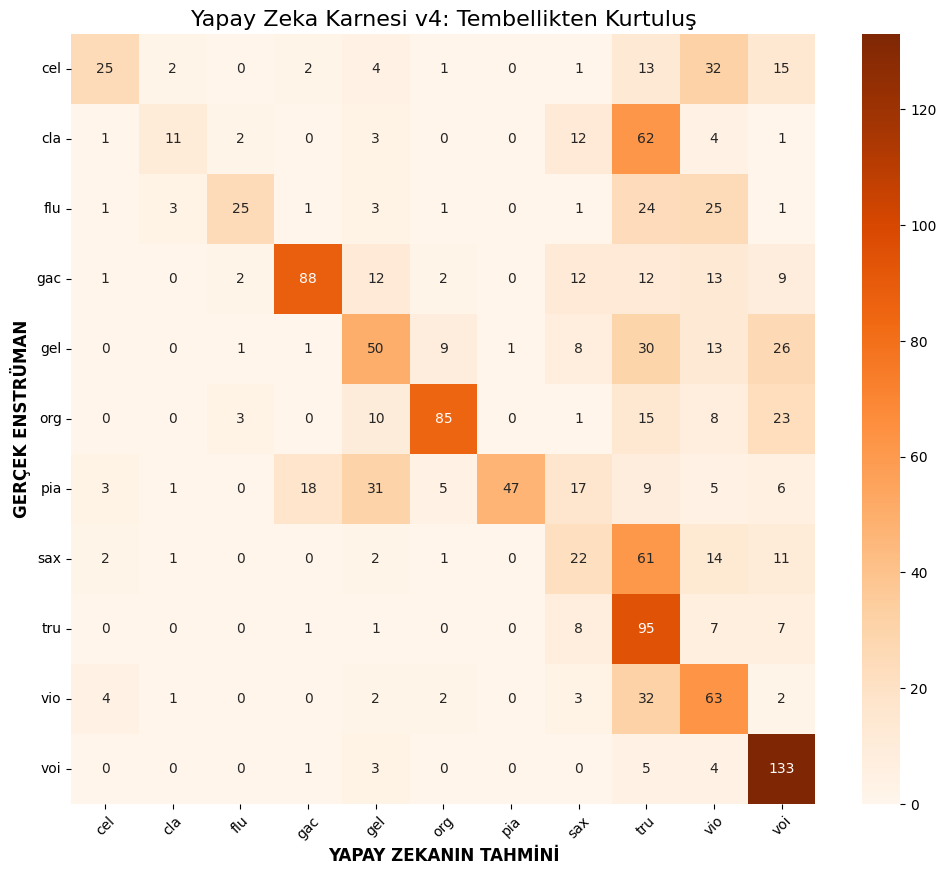


--- Yeni Model v4 Sınıflandırma Raporu ---
              precision    recall  f1-score   support

         cel       0.68      0.26      0.38        95
         cla       0.58      0.11      0.19        96
         flu       0.76      0.29      0.42        85
         gac       0.79      0.58      0.67       151
         gel       0.41      0.36      0.38       139
         org       0.80      0.59      0.68       145
         pia       0.98      0.33      0.49       142
         sax       0.26      0.19      0.22       114
         tru       0.27      0.80      0.40       119
         vio       0.34      0.58      0.42       109
         voi       0.57      0.91      0.70       146

    accuracy                           0.48      1341
   macro avg       0.58      0.46      0.45      1341
weighted avg       0.59      0.48      0.47      1341



In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

print("Model v4 için yeni röntgen çekiliyor...")

test_tahminleri_v4 = model_v4.predict(X_test_norm)
y_pred_v4 = np.argmax(test_tahminleri_v4, axis=1)

cm_v4 = confusion_matrix(y_test, y_pred_v4)

plt.figure(figsize=(12, 10))
sns.heatmap(cm_v4, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=sinif_isimleri, 
            yticklabels=sinif_isimleri)

plt.title('Yapay Zeka Karnesi v4: Tembellikten Kurtuluş', fontsize=16)
plt.ylabel('GERÇEK ENSTRÜMAN', fontsize=12, fontweight='bold')
plt.xlabel('YAPAY ZEKANIN TAHMİNİ', fontsize=12, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

print("\n--- Yeni Model v4 Sınıflandırma Raporu ---")
print(classification_report(y_test, y_pred_v4, target_names=sinif_isimleri))

**Karşılaştırma (v3 vs v4):** Veri artırma (kaydırma + yakınlaştırma) ile eğitilen v4, genel doğrulukta v3'ün bir miktar gerisinde kalmıştır (v4: %48, v3: %53). Buna karşın v4 bazı sınıflarda (akustik gitar, org) F1 skorunu artırmış; piyano sınıfında çok yüksek kesinlik (precision = 0,98) üretmiştir. Artırmanın etkisini tam gösterebilmesi için daha uzun eğitim ve ayrı bir doğrulama seti gerekmektedir. Streamlit uygulaması (app.py) v4 modelini kullanmaktadır.

In [8]:
model_v4.save('multi_instrument_model_v4.keras')
print("Model başarıyla diske kaydedildi!")

Model başarıyla diske kaydedildi!


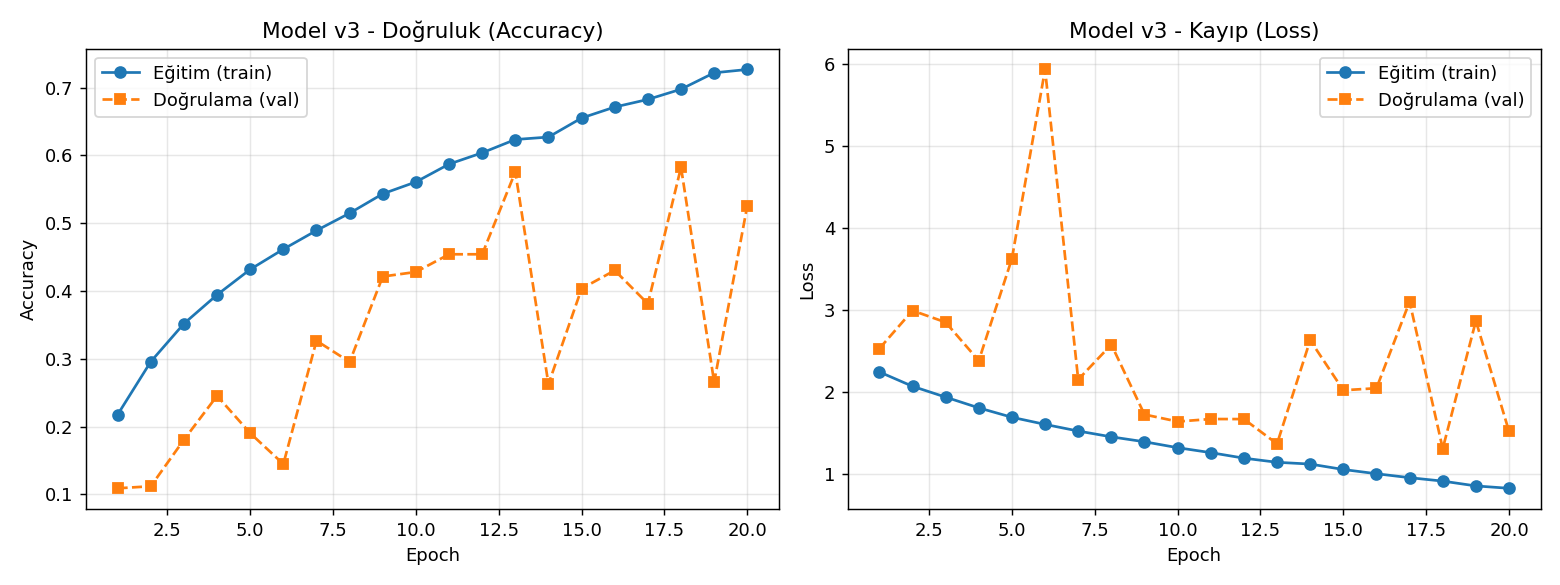

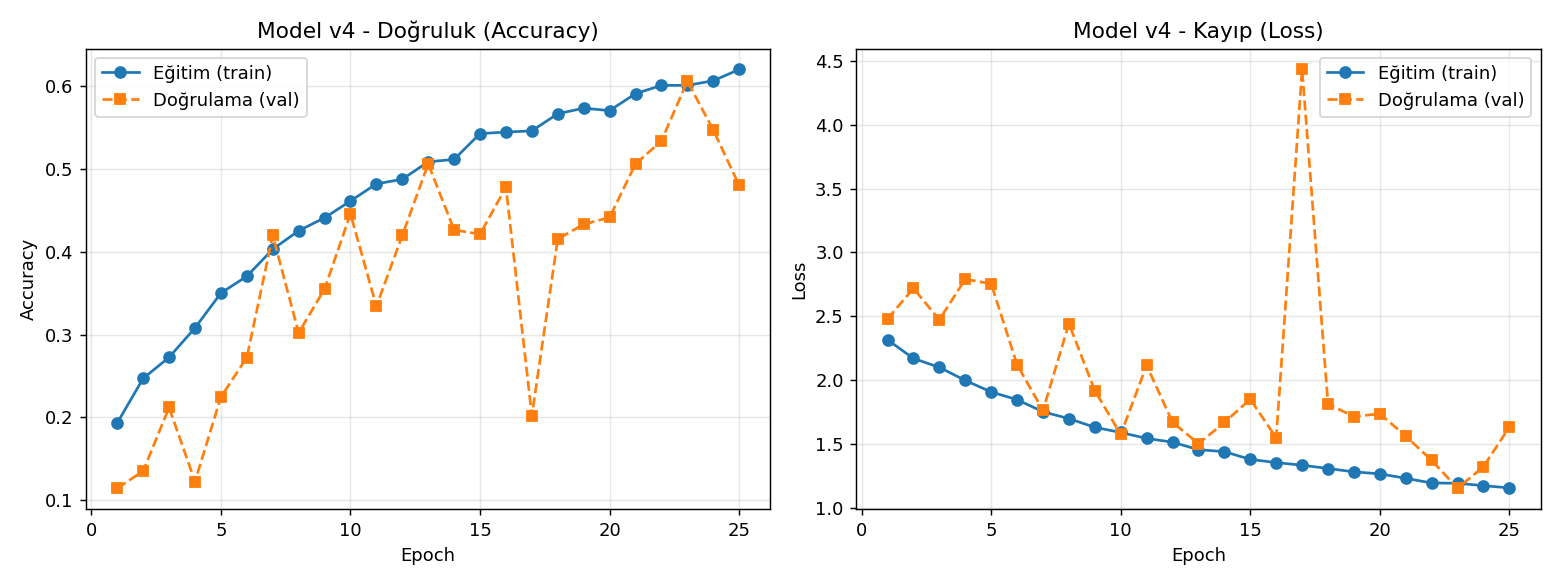

In [9]:
import matplotlib.pyplot as plt

def egitim_egrileri(history, baslik):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(history.history['accuracy'], 'o-', label='Eğitim')
    axes[0].plot(history.history['val_accuracy'], 's--', label='Doğrulama')
    axes[0].set_title(f'{baslik} - Doğruluk (Accuracy)')
    axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(history.history['loss'], 'o-', label='Eğitim')
    axes[1].plot(history.history['val_loss'], 's--', label='Doğrulama')
    axes[1].set_title(f'{baslik} - Kayıp (Loss)')
    axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

egitim_egrileri(history_v3, 'Model v3 (20 epoch)')
egitim_egrileri(history_v4, 'Model v4 (25 epoch)')

# Sonuçların Yorumlanması, Hata Analizi ve Öneriler

## Güçlü Yönler
- İnsan sesi (v3 F1 = 0,74) ve akustik gitar, org gibi tınısı belirgin sınıflar yüksek başarıyla ayrıştırılmaktadır.
- Dört model varyantı (v1 → v4) sistematik biçimde karşılaştırılmış; BatchNorm, GlobalAveragePooling ve veri artırma gibi iyileştirmelerin etkisi ölçülmüştür.
- Uçtan uca çalışan bir çıkarım hattı kurulmuştur: `03_test_ve_tahmin.ipynb` ile tek dosya tahmini ve `app.py` ile canlı Streamlit demosu.

## Zayıf Yönler ve Hatalar
- Genel test doğruluğu %53 civarındadır; 11 sınıflı bir problem için mütevazı bir seviyedir.
- Klarnet (F1 = 0,33) ve saksafon (F1 = 0,33) en çok karışan sınıflardır. Karmaşıklık matrisinde bu sınıfların birbirine ve flüt/çello gibi benzer tınılı sınıflara karıştığı görülmektedir; bu enstrümanların harmonik yapıları ve perde aralıkları örtüşmektedir.
- Eğitim doğruluğu (%72) ile doğrulama doğruluğu (%53) arasındaki fark belirgin bir ezberleme (overfitting) eğilimine işaret etmektedir.
- **Metodolojik not:** Ayrı bir doğrulama seti ayrılmamış, doğrulama için test seti kullanılmıştır; bu durum model seçimini iyimserleştirebilir. Ayrıca normalizasyon her veri bölmesi için ayrı hesaplanmıştır.
- Sınıf dengesizliği (388–778) telafi edilmemiştir.
- IRMAS çok etiketli bir veri setidir; projede yalnızca birincil etiket kullanıldığı için ikincil enstrümanlar modele gürültü olarak yansımaktadır.

## Geliştirme Önerileri
1. Eğitim/doğrulama/test üçlü bölme; erken durdurma (early stopping) ve öğrenme oranı zamanlayıcısı kullanımı.
2. Sınıf ağırlıkları (class weights) veya azınlık sınıflarına yönelik veri artırma ile dengesizliğin giderilmesi.
3. Mel-spektrograma ek olarak MFCC, kromagram ve spektral kontrast özniteliklerinin birleştirilmesi.
4. Transfer learning (önceden eğitilmiş ses modellerinden özellik çıkarımı) veya CRNN (CNN + RNN) mimarilerinin denenmesi.
5. Çok etiketli (multi-label) sınıflandırmaya geçilerek ikincil enstrümanların da modellenmesi.
6. Test zamanı artırma (TTA) ve model topluluğu (ensemble) ile kararlılığın artırılması.